In [17]:
import pandas as pd

ds = pd.read_csv("../datasets/autompg.csv")

X = ds[["displacement"]]
Y = ds["class"]


In [18]:
from sklearn.model_selection import train_test_split
import numpy as np

xtr, xte, ytr, yte = train_test_split(X, Y, test_size=0.2)

sort_idx = xte["displacement"].argsort()
xte = xte.iloc[sort_idx]
yte = yte.iloc[sort_idx]

from sklearn.preprocessing import StandardScaler

sc = StandardScaler()

xtr = sc.fit_transform(xtr)
xte = sc.transform(xte)

-----Linear Regression----
MSE : 29.161387556938713
R2S : 0.5817613275944908
-----Polynomial Regression----
MSE : 25.848274322921107
R2S : 0.6292786851900122


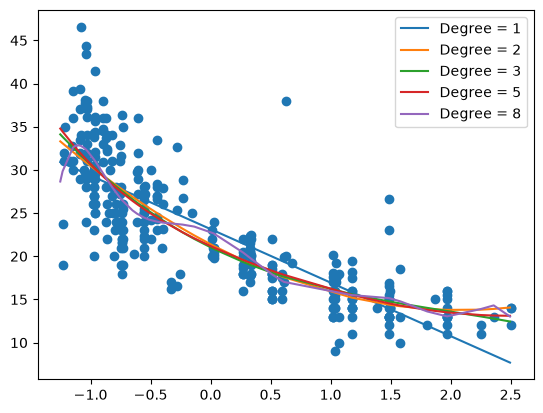

In [20]:
# Linear Regression
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np
import matplotlib.pyplot as plt

lr = LinearRegression()
lr.fit(xtr, ytr)
y1 = lr.predict(xte)

print("-----Linear Regression----")
print(f"MSE : {mean_squared_error(yte, y1)}")
print(f"R2S : {r2_score(yte, y1)}")

# Polynomial Regression
degree = [1, 2, 3, 5, 8]

mse = []
r2 = []
for d in degree:
    p = PolynomialFeatures(degree=d)
    xtr_poly = p.fit_transform(xtr)
    xte_poly = p.transform(xte)

    lrp = LinearRegression()
    lrp.fit(xtr_poly, ytr)
    y = lrp.predict(xte_poly)
    mse.append(mean_squared_error(yte, y))
    r2.append(r2_score(yte, y))
    plt.plot(xte, y, label=f"Degree = {d}")
    
plt.scatter(xtr, ytr)
print("-----Polynomial Regression----")
print(f"MSE : {np.mean(mse)}")
print(f"R2S : {np.mean(r2)}")

plt.legend()
plt.show()